In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
df = pd.read_csv(
    'sales_data_sample.csv',
    encoding='unicode_escape'
)

df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   str    
 6   STATUS            2823 non-null   str    
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   str    
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   str    
 13  CUSTOMERNAME      2823 non-null   str    
 14  PHONE             2823 non-null   str    
 15  ADDRESSLINE1      2823 non-null   str    
 16  ADDRESSLINE2      302 non-null    str    
 17  CITY  

In [11]:
df_drop = [
    'ADDRESSLINE1',
    'ADDRESSLINE2',
    'POSTALCODE',
    'CITY',
    'TERRITORY',
    'PHONE',
    'STATE',
    'CONTACTFIRSTNAME',
    'CONTACTLASTNAME',
    'CUSTOMERNAME',
    'ORDERNUMBER'
]

df = df.drop(df_drop, axis=1)

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   QUANTITYORDERED  2823 non-null   int64  
 1   PRICEEACH        2823 non-null   float64
 2   ORDERLINENUMBER  2823 non-null   int64  
 3   SALES            2823 non-null   float64
 4   ORDERDATE        2823 non-null   str    
 5   STATUS           2823 non-null   str    
 6   QTR_ID           2823 non-null   int64  
 7   MONTH_ID         2823 non-null   int64  
 8   YEAR_ID          2823 non-null   int64  
 9   PRODUCTLINE      2823 non-null   str    
 10  MSRP             2823 non-null   int64  
 11  PRODUCTCODE      2823 non-null   str    
 12  COUNTRY          2823 non-null   str    
 13  DEALSIZE         2823 non-null   str    
dtypes: float64(2), int64(6), str(6)
memory usage: 308.9 KB


In [13]:
for col in df.columns.values:
    print(df[col].value_counts())

QUANTITYORDERED
34    112
21    103
46    101
27    100
41     97
45     97
31     97
26     96
29     94
48     94
25     94
20     93
22     92
33     92
49     91
24     91
38     91
32     91
36     89
44     89
37     87
43     85
39     84
28     82
40     78
42     76
30     75
23     73
35     71
47     70
50     65
55     16
66      5
51      4
15      4
56      3
64      3
19      3
61      3
59      3
76      3
60      3
18      3
10      2
54      2
6       2
70      2
11      2
12      1
97      1
65      1
58      1
16      1
13      1
52      1
62      1
85      1
77      1
Name: count, dtype: int64
PRICEEACH
100.00    1304
96.34        6
59.87        6
61.99        5
89.38        5
          ... 
50.78        1
59.51        1
55.69        1
97.16        1
62.24        1
Name: count, Length: 1016, dtype: int64
ORDERLINENUMBER
1     307
2     291
3     270
4     256
5     239
6     221
7     197
8     187
9     165
10    141
11    128
12    110
13     97
14     81
15     

In [14]:
df.drop(columns=['ORDERDATE','STATUS','MONTH_ID','QTR_ID','YEAR_ID'],inplace=True)
df.head()

,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,PRODUCTLINE,MSRP,PRODUCTCODE,COUNTRY,DEALSIZE
0,30,95.70,2,2871.00,Motorcycles,95,S10_1678,USA,Small
1,34,81.35,5,2765.90,Motorcycles,95,S10_1678,France,Small
2,41,94.74,2,3884.34,Motorcycles,95,S10_1678,France,Medium
3,45,83.26,6,3746.70,Motorcycles,95,S10_1678,USA,Medium
4,49,100.00,14,5205.27,Motorcycles,95,S10_1678,USA,Medium


In [15]:
df.isnull().sum()

QUANTITYORDERED    0
PRICEEACH          0
ORDERLINENUMBER    0
SALES              0
PRODUCTLINE        0
MSRP               0
PRODUCTCODE        0
COUNTRY            0
DEALSIZE           0
dtype: int64

In [16]:
df.dropna(inplace=True)
df.reset_index(drop=True,inplace=True)
df.shape

(2823, 9)

In [17]:
from sklearn.preprocessing import LabelEncoder

def convert_categories(col):
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].values)

In [18]:
categories = [
    'PRODUCTLINE',
    'PRODUCTCODE',
    'COUNTRY',
    'DEALSIZE'
]

for col in categories:
    convert_categories(col)

In [19]:
df.head()

,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,PRODUCTLINE,MSRP,PRODUCTCODE,COUNTRY,DEALSIZE
0,30,95.70,2,2871.00,1,95,0,18,2
1,34,81.35,5,2765.90,1,95,0,6,2
2,41,94.74,2,3884.34,1,95,0,6,1
3,45,83.26,6,3746.70,1,95,0,18,1
4,49,100.00,14,5205.27,1,95,0,18,1


In [20]:
from sklearn.preprocessing import StandardScaler
feature_names=df.columns.tolist()
sc=StandardScaler()
data=sc.fit_transform(df)
print("Scaled data shape:",data.shape)

Scaled data shape: (2823, 9)


In [21]:
from sklearn.cluster import KMeans

wcss = []

for k in range(1, 15):

    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        random_state=15,
        n_init=10
    )

    kmeans.fit(data)

    wcss.append(kmeans.inertia_)

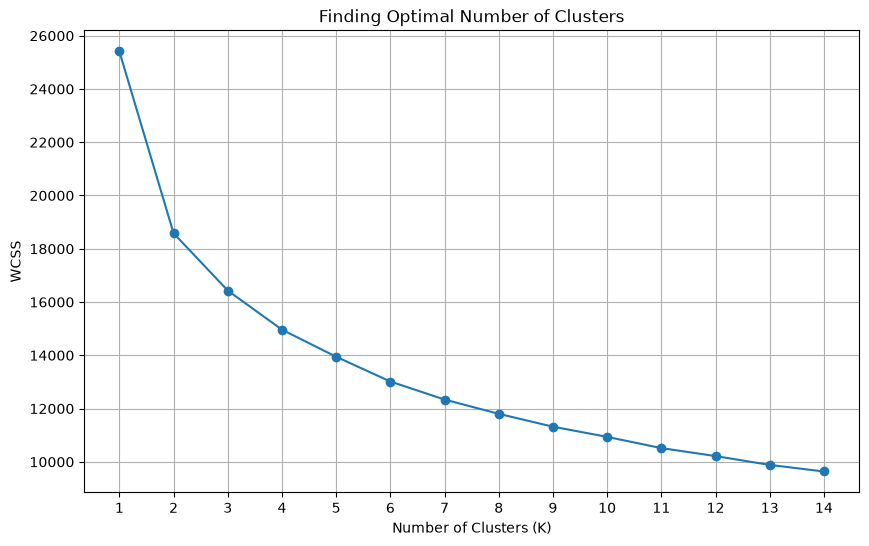

In [22]:
k = list(range(1, 15))
plt.figure(figsize=(10, 6))
plt.plot(k, wcss, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Finding Optimal Number of Clusters')
plt.grid()
plt.xticks(k)
plt.show()

In [23]:
kmeans = KMeans(
    n_clusters=4,
    init='k-means++',
    random_state=15,
    n_init=10
)

y_kmeans = kmeans.fit_predict(data)

df['Cluster'] = y_kmeans

df.head()

,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,PRODUCTLINE,MSRP,PRODUCTCODE,COUNTRY,DEALSIZE,Cluster
0,30,95.70,2,2871.00,1,95,0,18,2,3
1,34,81.35,5,2765.90,1,95,0,6,2,3
2,41,94.74,2,3884.34,1,95,0,6,1,0
3,45,83.26,6,3746.70,1,95,0,18,1,0
4,49,100.00,14,5205.27,1,95,0,18,1,0


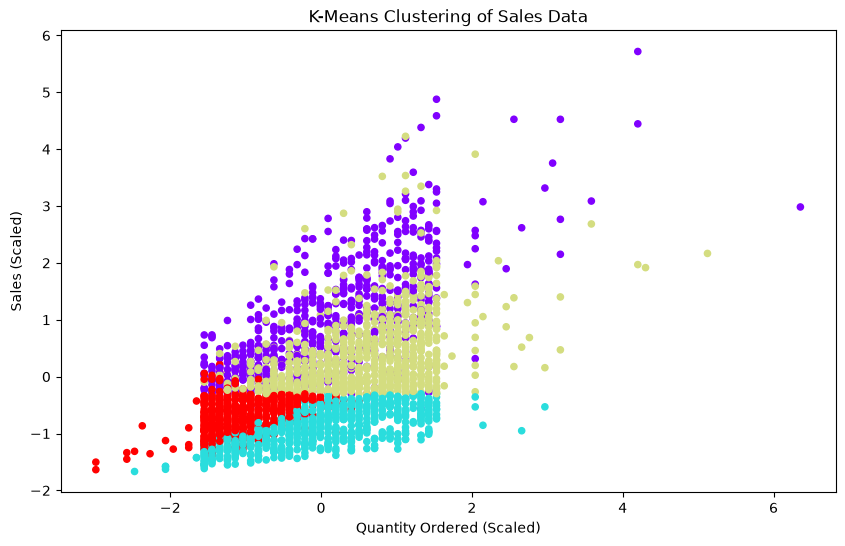

In [24]:
plt.figure(figsize=(10, 6))

x_index = feature_names.index('QUANTITYORDERED')
y_index = feature_names.index('SALES')

plt.scatter(
    data[:, x_index],
    data[:, y_index],
    c=y_kmeans,
    cmap='rainbow',
    s=20
)

plt.title('K-Means Clustering of Sales Data')

plt.xlabel('Quantity Ordered (Scaled)')

plt.ylabel('Sales (Scaled)')

plt.show()

In [25]:
print("Optimal Number of Clusters: 4")

print("\nCluster Distribution:")

print(df['Cluster'].value_counts().sort_index())

Optimal Number of Clusters: 4

Cluster Distribution:
Cluster
0    662
1    676
2    870
3    615
Name: count, dtype: int64


In [26]:
print("Cluster Centers:")

print(kmeans.cluster_centers_)

Cluster Centers:
[[ 0.17100076  0.76651387 -0.07636903  1.0435811  -0.70100164  1.3092751
  -1.03157764 -0.03880427 -0.99146008]
 [-0.00952893 -1.4856376   0.00345519 -0.91089406  0.30479995 -1.03260029
   0.42042842  0.02904649  1.01535268]
 [ 0.58939332  0.46323397 -0.00559562  0.3970465   0.35604468 -0.11532728
   0.33730514  0.08187835 -0.7173431 ]
 [-1.00737096  0.15259396  0.08632322 -0.68376709 -0.08413098 -0.1111668
   0.17112082 -0.10598564  0.96594579]]
